In [1]:
import os
import joblib
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from scipy.sparse import load_npz
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.ensemble import VotingClassifier
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

## 11. Loading Preprocessed Data


In [2]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [3]:
data_dir = '/content/drive/MyDrive/DataSets/Text Dataset/Preprocessed Data'

In [4]:
X_train_tfidf = load_npz(data_dir + '/X_train_tfidf.npz')

X_val_tfidf = load_npz(data_dir + '/X_val_tfidf.npz')

X_test_tfidf = load_npz(data_dir + '/X_test_tfidf.npz')

In [5]:
y_train = pd.read_csv(data_dir + '/y_train.csv')['sentiment']

y_val = pd.read_csv(data_dir + '/y_val.csv')['sentiment']

y_test = pd.read_csv(data_dir + '/y_test.csv')['sentiment']

In [6]:
print("Training Features:", X_train_tfidf.shape)
print("Validation Features:", X_val_tfidf.shape)
print("Testing Features:", X_test_tfidf.shape)

print("\nTraining Labels:", y_train.shape)
print("Validation Labels:", y_val.shape)
print("Testing Labels:", y_test.shape)


Training Features: (34707, 86316)
Validation Features: (7437, 86316)
Testing Features: (7438, 86316)

Training Labels: (34707,)
Validation Labels: (7437,)
Testing Labels: (7438,)


## 12. Logistic Regression Model

In [7]:
lr_model = LogisticRegression(max_iter=1000, random_state=42)
lr_model.fit(X_train_tfidf,y_train)

LogisticRegression(max_iter=1000, random_state=42)

In [8]:
y_val_pred_lr= lr_model.predict(X_val_tfidf)


In [9]:
lr_val_accuracy= accuracy_score(y_val, y_val_pred_lr)
print("Logistics Regression validation Accuracy: ", lr_val_accuracy)

Logistics Regression validation Accuracy:  0.8956568508807314


In [10]:
print("Logistics Regression Classification Report:\n")
print(classification_report(y_val, y_val_pred_lr))

Logistics Regression Classification Report:

              precision    recall  f1-score   support

    negative       0.91      0.88      0.89      3705
    positive       0.88      0.91      0.90      3732

    accuracy                           0.90      7437
   macro avg       0.90      0.90      0.90      7437
weighted avg       0.90      0.90      0.90      7437



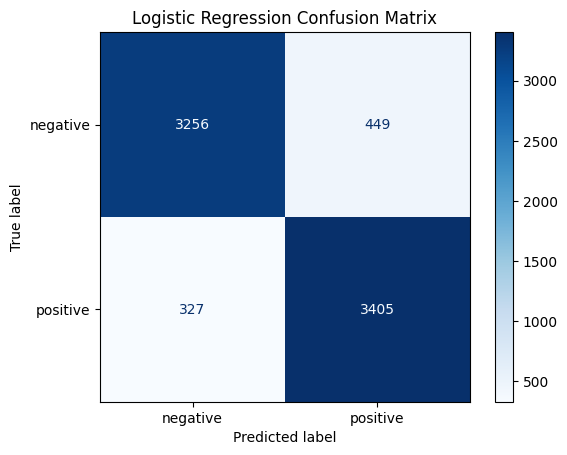

In [11]:
cm_lr = confusion_matrix(y_val, y_val_pred_lr, labels=['negative', 'positive'])
disp = ConfusionMatrixDisplay(confusion_matrix=cm_lr, display_labels=['negative', 'positive'])
disp.plot(cmap='Blues')
plt.title("Logistic Regression Confusion Matrix")
plt.show()

## 13. Logistic Regression Hyperparameter Tuning


In [12]:
C_values=[0.01,0.1,1,10,100]
lr_result=[]
for c in C_values:
  model=LogisticRegression(C=c, max_iter=1000, random_state=42)
  model.fit(X_train_tfidf,y_train)
  val_predection=model.predict(X_val_tfidf)
  val_accuracy=accuracy_score(y_val, val_predection)
  lr_result.append({'C':c,'Validation Accuracy':val_accuracy})
  print(f"C = {c}, Validation Accuracy = {val_accuracy:.4f}")

C = 0.01, Validation Accuracy = 0.8171
C = 0.1, Validation Accuracy = 0.8663
C = 1, Validation Accuracy = 0.8957
C = 10, Validation Accuracy = 0.8982
C = 100, Validation Accuracy = 0.8922


In [13]:
lr_result_df=pd.DataFrame(lr_result)
display(lr_result_df)

,C,Validation Accuracy
0,0.01,0.817131
1,0.10,0.866344
2,1.00,0.895657
3,10.00,0.898212
4,100.00,0.892161


In [14]:
best_lr_result=lr_result_df.loc[lr_result_df['Validation Accuracy'].idxmax()]
best_lr_C=best_lr_result['C']
print("Best C Value:", best_lr_C)
print(
    "Best Validation Accuracy:",
    best_lr_result['Validation Accuracy']
)

Best C Value: 10.0
Best Validation Accuracy: 0.8982116444803012


In [15]:
best_lr_model=LogisticRegression(C=best_lr_C, max_iter=1000, random_state=42)
best_lr_model.fit(X_train_tfidf,y_train)
best_lr_val_pred=best_lr_model.predict(X_val_tfidf)
best_lr_val_accuracy=accuracy_score(y_val, best_lr_val_pred)
print("Best Logistic Regression Validation Accuracy:", best_lr_val_accuracy)

Best Logistic Regression Validation Accuracy: 0.8982116444803012


## 14. Linear SVM Model


In [16]:
svm_model=LinearSVC(random_state=42,max_iter=5000)
svm_model.fit(X_train_tfidf,y_train)

LinearSVC(max_iter=5000, random_state=42)

In [17]:
y_val_pred_svm=svm_model.predict(X_val_tfidf)

In [18]:
svm_accuracy= accuracy_score(y_val, y_val_pred_svm)
print("Linear SVM validation Accuracy: ", svm_accuracy)

Linear SVM validation Accuracy:  0.8974048675541213


In [19]:
print("Linear SVM classification report:\n")
print(classification_report(y_val,y_val_pred_svm))

Linear SVM classification report:

              precision    recall  f1-score   support

    negative       0.90      0.89      0.90      3705
    positive       0.89      0.91      0.90      3732

    accuracy                           0.90      7437
   macro avg       0.90      0.90      0.90      7437
weighted avg       0.90      0.90      0.90      7437



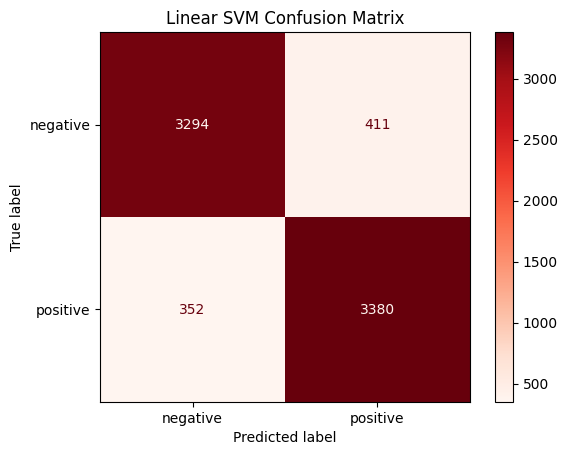

In [20]:
cm_svm=confusion_matrix(y_val, y_val_pred_svm, labels=['negative','positive'])
disp_svm=ConfusionMatrixDisplay(confusion_matrix=cm_svm, display_labels=['negative','positive'])
disp_svm.plot(cmap='Reds')
plt.title("Linear SVM Confusion Matrix")
plt.show()

## 15. Linear SVM Hyperparameter Tuning


In [21]:
svm_C_values=[0.01,0.1,1,10,100]
svm_results=[]
for c in svm_C_values:
  model=LinearSVC(C=c, random_state=42, max_iter=5000)
  model.fit(X_train_tfidf,y_train)
  y_pred = model.predict(X_val_tfidf)
  accuracy = accuracy_score(y_val, y_pred)
  svm_results.append({'C': c, 'Validation Accuracy': accuracy})
  print(f"C = {c}, Validation Accuracy = {accuracy:.4f}")

C = 0.01, Validation Accuracy = 0.8641
C = 0.1, Validation Accuracy = 0.8975
C = 1, Validation Accuracy = 0.8974
C = 10, Validation Accuracy = 0.8825
C = 100, Validation Accuracy = 0.8762


In [22]:
svm_result_df=pd.DataFrame(svm_results)
display(svm_result_df)

,C,Validation Accuracy
0,0.01,0.864058
1,0.10,0.897539
2,1.00,0.897405
3,10.00,0.882479
4,100.00,0.876160


In [23]:
best_svm_result = max(svm_results,key=lambda x: x['Validation Accuracy']
)
best_svm_C = best_svm_result['C']
best_svm_accuracy = best_svm_result['Validation Accuracy']
print("Best SVM C:", best_svm_C)
print("Best SVM Validation Accuracy:", best_svm_accuracy)

Best SVM C: 0.1
Best SVM Validation Accuracy: 0.8975393303751513


In [24]:
best_svm_model=LinearSVC(C=best_svm_C, random_state=42,max_iter=5000)
best_svm_model.fit(X_train_tfidf,y_train)
best_svm_val_pred=best_svm_model.predict(X_val_tfidf)

In [25]:
print("Best SVM C:", best_svm_C)
print("Best SVM Validation Accuracy:",
      accuracy_score(y_val, best_svm_val_pred ))

Best SVM C: 0.1
Best SVM Validation Accuracy: 0.8975393303751513


## 16. Model Comparison


In [26]:
comparison_results = {
    'Model': ['Logistic Regression (Baseline)','Logistic Regression (Tuned)',
               'Linear SVM (Baseline)','Linear SVM (Tuned)'],
    'Validation Accuracy': [lr_val_accuracy, best_lr_val_accuracy,
                            svm_accuracy, best_svm_accuracy]
}
comparison_df = pd.DataFrame(comparison_results)
comparison_df = comparison_df.sort_values(by='Validation Accuracy',ascending=False
).reset_index(drop=True)
display(comparison_df)


,Model,Validation Accuracy
0,Logistic Regression (Tuned),0.898212
1,Linear SVM (Tuned),0.897539
2,Linear SVM (Baseline),0.897405
3,Logistic Regression (Baseline),0.895657


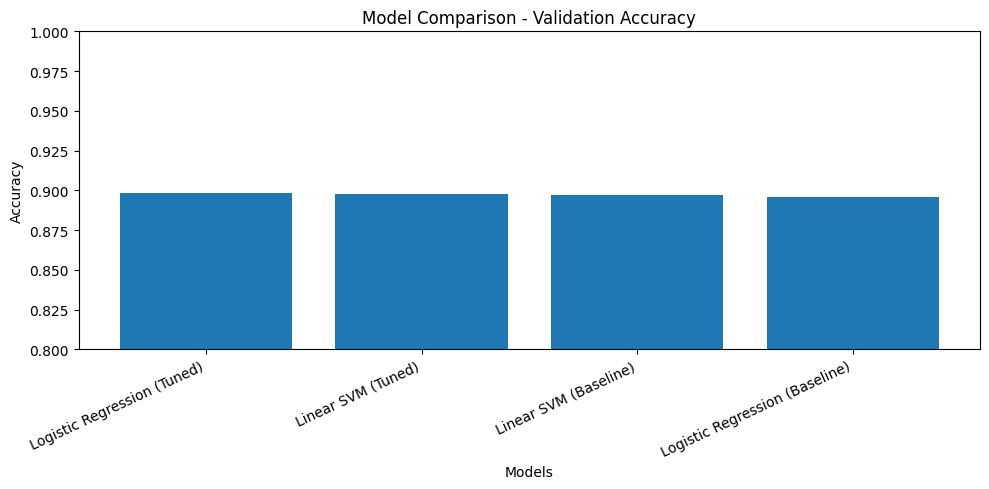

In [27]:
plt.figure(figsize=(10, 5))
plt.bar(
    comparison_df['Model'],
    comparison_df['Validation Accuracy']
)
plt.title('Model Comparison - Validation Accuracy')
plt.xlabel('Models')
plt.ylabel('Accuracy')
plt.xticks(rotation=25, ha='right')
plt.ylim(0.80, 1.0)
plt.tight_layout()
plt.show()

##17. Bonus – Voting Classifier

In [28]:
voting_model=VotingClassifier(estimators=[
    ('lr',LogisticRegression(C=best_lr_C,max_iter=1000,random_state=42)),
    ('svm',LinearSVC(C=best_svm_C,random_state=42,max_iter=5000))
],voting='hard')

In [29]:
voting_model.fit(X_train_tfidf,y_train)

VotingClassifier(estimators=[('lr',
                              LogisticRegression(C=np.float64(10.0),
                                                 max_iter=1000,
                                                 random_state=42)),
                             ('svm',
                              LinearSVC(C=0.1, max_iter=5000,
                                        random_state=42))])

In [30]:
y_val_pred_voting=voting_model.predict(X_val_tfidf)
voting_accuracy=accuracy_score(y_val,y_val_pred_voting)
print("Voting Classifier validation Accuracy: ", voting_accuracy)

Voting Classifier validation Accuracy:  0.900094123974721


In [31]:
print("Voting Classifier Classification Report:\n")
print(classification_report(y_val,y_val_pred_voting))

Voting Classifier Classification Report:

              precision    recall  f1-score   support

    negative       0.89      0.91      0.90      3705
    positive       0.91      0.89      0.90      3732

    accuracy                           0.90      7437
   macro avg       0.90      0.90      0.90      7437
weighted avg       0.90      0.90      0.90      7437



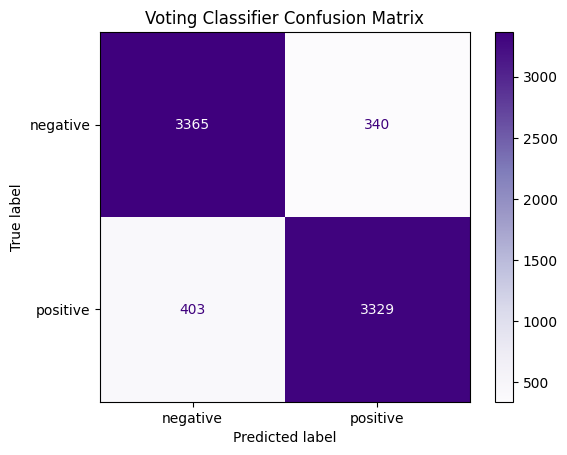

In [32]:
cm_voting= confusion_matrix(y_val, y_val_pred_voting, labels=['negative','positive'])
disp_voting=ConfusionMatrixDisplay(confusion_matrix=cm_voting,display_labels=['negative','positive'])
disp_voting.plot(cmap='Purples')
plt.title("Voting Classifier Confusion Matrix")
plt.show()

##18. Comparison of Tuned Models and Voting Classifier

In [33]:
final_validation_results={
    'Model':['Tuned Logistic Regression','Tuned Linear SVM','Voting Classifier'],
    'Validation Accuracy':[best_lr_val_accuracy,best_svm_accuracy,voting_accuracy]
}
final_validation_df=pd.DataFrame(final_validation_results)
final_validation_df=final_validation_df.sort_values(by='Validation Accuracy',ascending=False).reset_index(drop=True)
display(final_validation_df)


,Model,Validation Accuracy
0,Voting Classifier,0.900094
1,Tuned Logistic Regression,0.898212
2,Tuned Linear SVM,0.897539


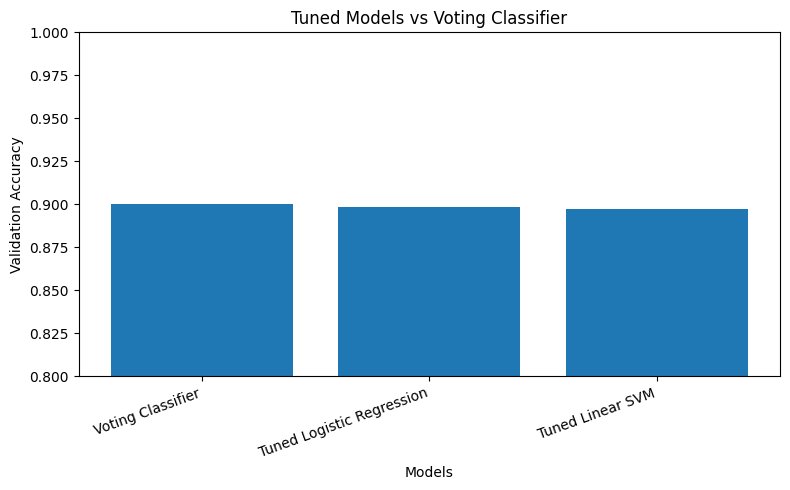

In [34]:
plt.figure(figsize=(8,5))
plt.bar(final_validation_df['Model'],final_validation_df['Validation Accuracy'])
plt.title('Tuned Models vs Voting Classifier')
plt.xlabel('Models')
plt.ylabel('Validation Accuracy')
plt.xticks(rotation=20,ha='right')
plt.ylim(0.80,1.0)
plt.tight_layout()
plt.show()

##19. Final Test Evaluation

In [35]:
y_test_pred_lr=best_lr_model.predict(X_test_tfidf)
y_test_pred_svm=best_svm_model.predict(X_test_tfidf)
y_test_pred_voting=voting_model.predict(X_test_tfidf)

In [36]:
def evaluate_model(model_name,y_true,y_pred):
  print("="*60)
  print(model_name)
  print("="*60)
  print("Accuracy: ",accuracy_score(y_true,y_pred))
  print("\nClassification Report:")
  print(classification_report(y_true,y_pred))
  cm=confusion_matrix(y_true,y_pred,labels=['negative','positive'])
  disp=ConfusionMatrixDisplay(confusion_matrix=cm,display_labels=['negative','positive'])
  disp.plot(cmap='hot')
  plt.title(f"{model_name} Confusion Matrix")
  plt.show()

Tuned Logistic Regression-Test Evaluation
Accuracy:  0.9002420005377789

Classification Report:
              precision    recall  f1-score   support

    negative       0.91      0.88      0.90      3705
    positive       0.89      0.92      0.90      3733

    accuracy                           0.90      7438
   macro avg       0.90      0.90      0.90      7438
weighted avg       0.90      0.90      0.90      7438



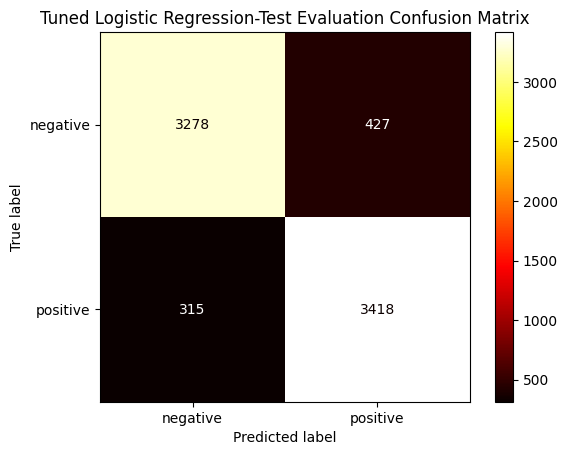

In [37]:
evaluate_model("Tuned Logistic Regression-Test Evaluation",y_test,y_test_pred_lr)

Tuned Linear SVM-Test Evaluation
Accuracy:  0.8962086582414628

Classification Report:
              precision    recall  f1-score   support

    negative       0.91      0.87      0.89      3705
    positive       0.88      0.92      0.90      3733

    accuracy                           0.90      7438
   macro avg       0.90      0.90      0.90      7438
weighted avg       0.90      0.90      0.90      7438



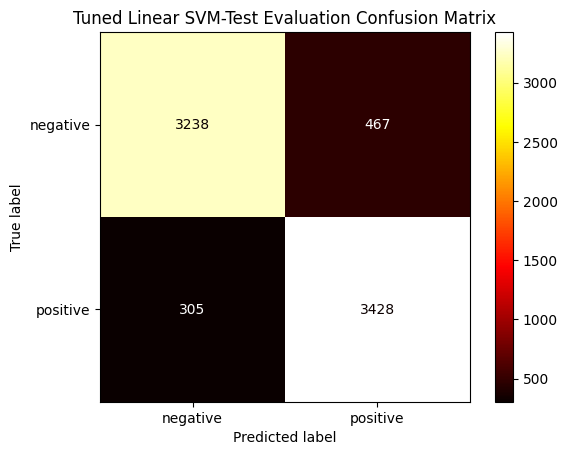

In [38]:
evaluate_model("Tuned Linear SVM-Test Evaluation",y_test,y_test_pred_svm)

Voting Classifier-Test Evaluation
Accuracy:  0.8997042215649368

Classification Report:
              precision    recall  f1-score   support

    negative       0.90      0.90      0.90      3705
    positive       0.90      0.90      0.90      3733

    accuracy                           0.90      7438
   macro avg       0.90      0.90      0.90      7438
weighted avg       0.90      0.90      0.90      7438



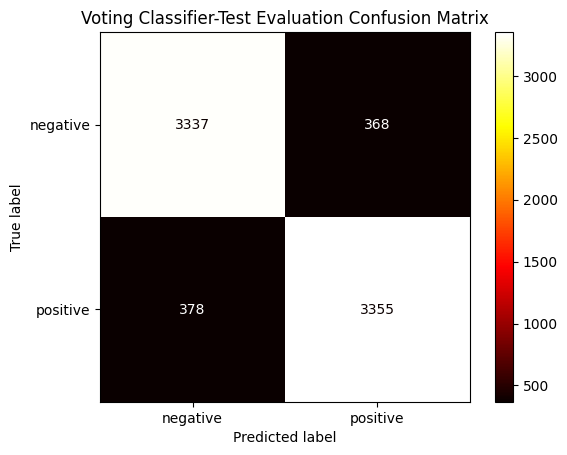

In [39]:
evaluate_model("Voting Classifier-Test Evaluation",y_test,y_test_pred_voting)

##20. Final Test Results

In [40]:
test_results={
    'Model':['Tuned Logistic Regression','Tuned Linear SVM','Voting Classifier'],
    'Test Accuracy':[accuracy_score(y_test,y_test_pred_lr),
                     accuracy_score(y_test,y_test_pred_svm),
                     accuracy_score(y_test,y_test_pred_voting)]
}
test_results_df=pd.DataFrame(test_results)
test_results_df=test_results_df.sort_values(by='Test Accuracy',ascending=False).reset_index(drop=True)
display(test_results_df)

,Model,Test Accuracy
0,Tuned Logistic Regression,0.900242
1,Voting Classifier,0.899704
2,Tuned Linear SVM,0.896209


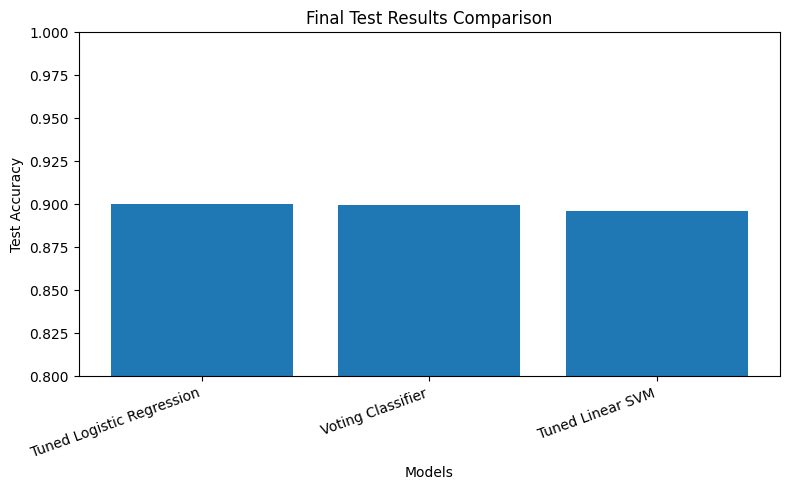

In [41]:
plt.figure(figsize=(8,5))
plt.bar(test_results_df['Model'],test_results_df['Test Accuracy'])
plt.title('Final Test Results Comparison')
plt.xlabel('Models')
plt.ylabel('Test Accuracy')
plt.xticks(rotation=20,ha='right')
plt.ylim(0.80,1.0)
plt.tight_layout()
plt.show()

In [47]:

# Create Models folder
models_path = os.path.join(data_dir, "Models")
os.makedirs(models_path, exist_ok=True)

# Load saved TF-IDF Vectorizer
tfidf_vectorizer = joblib.load(
    os.path.join(data_dir, "tfidf_vectorizer.joblib")
)

# Save trained models
joblib.dump(best_lr_model, os.path.join(models_path, "logistic_regression.pkl"))
joblib.dump(best_svm_model, os.path.join(models_path, "linear_svm.pkl"))
joblib.dump(voting_model, os.path.join(models_path, "voting_classifier.pkl"))

# Save TF-IDF Vectorizer
joblib.dump(tfidf_vectorizer, os.path.join(models_path, "tfidf_vectorizer.joblib"))

print("Text models saved successfully!")
print("\nSaved files:")
for file in os.listdir(models_path):
    print("-", file)

Text models saved successfully!

Saved files:
- logistic_regression.pkl
- linear_svm.pkl
- voting_classifier.pkl
- tfidf_vectorizer.joblib
